# HighDimensions

Notebook for exploring high-dimensional X.

In [1]:
import numpy as np

# Generate 1000 samples with 28000 features
# Each feature is normally distributed with mean=0 and std=1
X = np.random.normal(loc=0, scale=1, size=(1000, 28000))
X.shape

(1000, 28000)

In [2]:
# Split first 10 features into two groups and apply shifts
X[0:500, :10] += -3  # First 5 features shifted by -3
X[500:1000, :10] += 3  # Next 5 features shifted by +3

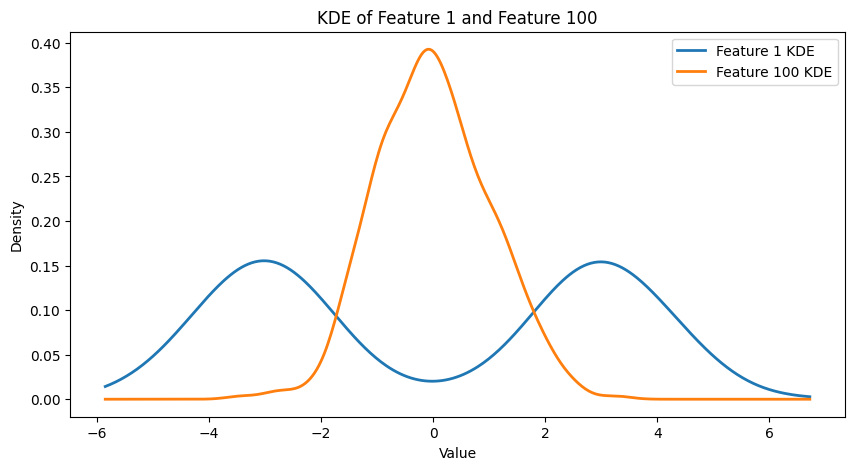

In [3]:
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

feature_1 = X[:, 0]
feature_100 = X[:, 99]

x_min = min(feature_1.min(), feature_100.min())
x_max = max(feature_1.max(), feature_100.max())
x_grid = np.linspace(x_min, x_max, 400)

kde_feature_1 = gaussian_kde(feature_1)
kde_feature_100 = gaussian_kde(feature_100)

plt.figure(figsize=(10, 5))
plt.plot(x_grid, kde_feature_1(x_grid), label='Feature 1 KDE', linewidth=2)
plt.plot(x_grid, kde_feature_100(x_grid), label='Feature 100 KDE', linewidth=2)
plt.xlabel('Value')
plt.ylabel('Density')
plt.title('KDE of Feature 1 and Feature 100')
plt.legend()
plt.show()

In [4]:
n_samples = X.shape[0]
y = np.zeros(n_samples, dtype=int)
y[n_samples // 2:] = 1

y.shape, np.bincount(y)
y[:10], y[490:510], y[-10:]

(array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0]),
 array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]),
 array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1]))

In [5]:
import pandas as pd

X_df = pd.DataFrame(X, columns=[f"feature_{i+1}" for i in range(X.shape[1])])
y_df = pd.DataFrame(y, columns=["y"])

X_df.shape, y_df.shape

((1000, 28000), (1000, 1))

Termination cause: converged by tolerance
Test accuracy: 0.565
Final loss: 0.08014153285732598


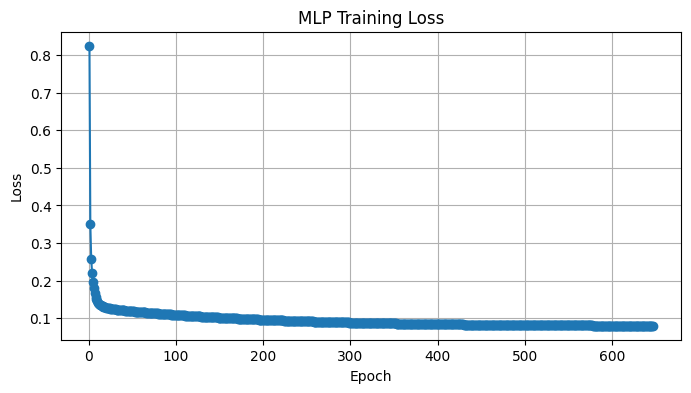

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Use X_df as input and y_df as output
X_data = X_df
y_data = y_df["y"].values  # convert DataFrame column to 1D array

# 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=42, stratify=y_data
)

# MLP model (100 epochs via max_iter=100)
mlp_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(4),
        activation="relu",
        solver="adam",
        tol=1e-5,
        max_iter=1000,
        random_state=40
    ))
])

# Train
mlp_pipeline.fit(X_train, y_train)

# Report termination cause
mlp_model = mlp_pipeline.named_steps["mlp"]
if mlp_model.n_iter_ >= mlp_model.max_iter:
    print("Termination cause: reached max_iter")
else:
    print("Termination cause: converged by tolerance")

# Evaluate
y_pred = mlp_pipeline.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))

# Plot loss curve
loss_values = mlp_pipeline.named_steps["mlp"].loss_curve_
print("Final loss:", loss_values[-1])
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(loss_values) + 1), loss_values, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP Training Loss")
plt.grid(True)
plt.show()

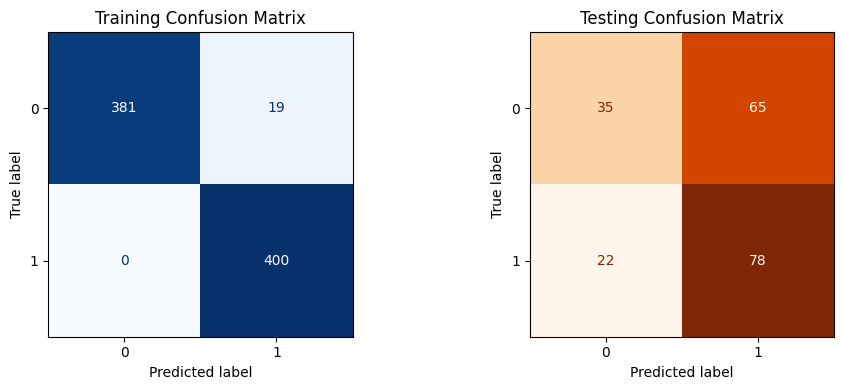

Training CM:
 [[381  19]
 [  0 400]]
Testing CM:
 [[35 65]
 [22 78]]


In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predictions
y_train_pred = mlp_pipeline.predict(X_train)
y_test_pred = mlp_pipeline.predict(X_test)

# Confusion matrices
cm_train = confusion_matrix(y_train, y_train_pred)
cm_test = confusion_matrix(y_test, y_test_pred)

# Plot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=[0, 1]).plot(
    ax=axes[0], cmap="Blues", colorbar=False
)
axes[0].set_title("Training Confusion Matrix")

ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=[0, 1]).plot(
    ax=axes[1], cmap="Oranges", colorbar=False
)
axes[1].set_title("Testing Confusion Matrix")

plt.tight_layout()
plt.show()

print("Training CM:\n", cm_train)
print("Testing CM:\n", cm_test)

In [13]:
from sklearn.metrics import f1_score

# Per-class F1 (class 0, class 1)
f1_per_class = f1_score(y_test, y_test_pred, average=None, labels=[0, 1])

# Combined F1 scores
f1_macro = f1_score(y_test, y_test_pred, average="macro")
f1_weighted = f1_score(y_test, y_test_pred, average="weighted")
f1_micro = f1_score(y_test, y_test_pred, average="micro")

print(f"F1 class 0: {f1_per_class[0]:.4f}")
print(f"F1 class 1: {f1_per_class[1]:.4f}")
print(f"F1 combined (macro): {f1_macro:.4f}")
print(f"F1 combined (weighted): {f1_weighted:.4f}")
print(f"F1 combined (micro): {f1_micro:.4f}")

F1 class 0: 0.4459
F1 class 1: 0.6420
F1 combined (macro): 0.5439
F1 combined (weighted): 0.5439
F1 combined (micro): 0.5650
